# 11 · Modelos base

**Fase CRISP-DM:** 4. Modelado

**Objetivo:** fijar la vara que el modelo principal (LightGBM, notebook 12) tiene que superar. Si un modelo complejo no le gana con claridad a algo simple, no se justifica.

| Modelo | Qué hace | Aprende de los datos |
|---|---|---|
| **Azar** | orden aleatorio | no (es el piso) |
| **Popularidad** | lo más pedido en el restaurante; si tiene poca historia, lo más pedido del canónico en la plataforma | solo el umbral `N` |
| **Contenido** | coincidencia del platillo con el perfil a la fecha (canónico, proteína, cocina, picante, precio), armada a mano | no |
| **Regresión logística** | combina todas las features con pesos aprendidos | sí |

**Métricas** (notebook 06: consultas chicas, casi siempre un solo positivo): **NDCG@3** es la principal, junto con HitRate@3, Recall@3 y MAP@3. Con una mediana de 5 candidatos por consulta, el top 5 casi siempre incluye todo, así que @5 se reporta pero dice poco.

**Todo se mide en validación (mes 10).** La prueba (meses 11 y 12) no se toca hasta el notebook 15.

**Entradas:** `data/Data_model/`. **Salidas:** `models/logistica_para_ti.joblib`, `models/logistica_para_la_mesa.joblib` y `data/Data_model/metricas_base_valid.parquet`.

> Este notebook solo narra el algoritmo. La lógica vive en `src/puzzle_recsys`.

## Configuración

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from puzzle_recsys.config import load_paths, load_simulation, load_yaml
from puzzle_recsys.evaluation.metrics import catalog_coverage, rank_metrics, summarize
from puzzle_recsys.ranking.baselines import content_score, popularity_score, random_score
from puzzle_recsys.ranking.feature_sets import FOR_TABLE, FOR_YOU, model_frame
from puzzle_recsys.ranking.logistic import make_logistic

paths, sim, mcfg = load_paths(), load_simulation(), load_yaml("models")
KS = tuple(mcfg["evaluation"]["k"])
SEED = sim.seed
ti = pd.read_parquet(paths.data_model / "para_ti.parquet")
ti = ti[ti["split"].isin(["train", "valid"])]  # la prueba no se lee aquí
train, valid = ti[ti["split"] == "train"], ti[ti["split"] == "valid"].copy()
segmentos = valid.drop_duplicates("query_id").set_index("query_id")[["course", "tramo_historia", "primera_vez_restaurante"]]
pd.DataFrame({"consultas": [train["query_id"].nunique(), valid["query_id"].nunique()],
              "filas": [len(train), len(valid)]}, index=["train", "valid"])

,consultas,filas
train,361470,2060781
valid,40056,235277


In [2]:
def evaluar(df, score, nombre):
    per_q = rank_metrics(df.assign(score=score), ks=KS, seed=SEED).assign(modelo=nombre)
    return per_q.join(segmentos, on="query_id")

resultados = {"azar": evaluar(valid, random_score(valid, seed=SEED), "azar")}
summarize(resultados["azar"]).round(3)

,consultas,ndcg@3,hit@3,recall@3,map@3,ndcg@5,hit@5,recall@5,map@5
0,40056,0.462,0.603,0.603,0.414,0.546,0.807,0.807,0.46


El **azar** no es cero porque las consultas son chicas: con 5 candidatos y un positivo, adivinar en el top 3 sale bien seguido. Es el piso.

## 1. Popularidad (jerarquía de respaldo)

Si el restaurante tiene al menos `N` pedidos previos en ese tipo de plato, se usa su popularidad; si no, la del canónico en toda la plataforma. Un `N` muy bajo confía en restaurantes con muy poca historia (ruido); uno muy alto desperdicia la información local. `N` se elige en validación.

In [3]:
grid = []
for n in [0, 5, 10, 25, 50, 100, 250, 500]:
    s = summarize(rank_metrics(valid.assign(score=popularity_score(valid, min_orders=n)), ks=(3,), seed=SEED))
    grid.append({"N": n, "ndcg@3": s["ndcg@3"].iloc[0], "% consultas con respaldo global":
                 100 * (valid.drop_duplicates("query_id")["pedidos_previos_restaurante"] < n).mean()})
grid = pd.DataFrame(grid)
N_BEST = int(grid.loc[grid["ndcg@3"].idxmax(), "N"])
display(grid.round(4))
resultados["popularidad"] = evaluar(valid, popularity_score(valid, min_orders=N_BEST), "popularidad")
pd.Series({"N elegido": N_BEST}).to_frame("valor").T

,N,ndcg@3,% consultas con respaldo global
0,0,0.6565,0.0000
1,5,0.6565,0.0649
2,10,0.6565,0.1323
3,25,0.6564,0.3745
4,50,0.6564,1.1908
5,100,0.6563,3.6025
6,250,0.6552,13.5410
7,500,0.6516,30.3775


,N elegido
valor,0


## 2. Similitud por contenido

Puntaje armado a mano con el perfil a la fecha: `log(1 + veces que pidió el canónico) + proporción de esa proteína + afinidad por la cocina - |diferencia de picante| / 3 - |ajuste de precio|`. Un dato faltante (primera visita) no suma ni resta. No aprende nada: mide cuánto vale "parecerse a lo que ya pediste".

In [4]:
resultados["contenido"] = evaluar(valid, content_score(valid), "contenido")
summarize(resultados["contenido"]).round(3)

,consultas,ndcg@3,hit@3,recall@3,map@3,ndcg@5,hit@5,recall@5,map@5
0,40056,0.649,0.793,0.793,0.6,0.703,0.922,0.922,0.629


## 3. Regresión logística

Combina las 33 features con pesos aprendidos (`ranking/logistic.py`). Todo el preprocesamiento está dentro de un `Pipeline` de scikit-learn, así que se aprende **solo con el entrenamiento**:

- Numéricas: mediana + indicador de faltante, y estandarización.
- Categóricas: one-hot con las 12 más frecuentes y "otras".
- Canónico: `TargetEncoder`, que codifica fuera de pliegue (notebook 10).

La regularización `C` se elige en validación.

In [5]:
Xtr, Xva = model_frame(train, FOR_YOU), model_frame(valid, FOR_YOU)
cols = list(FOR_YOU.columns)
busqueda, modelos = [], {}
for c in [0.01, 1.0]:
    m = make_logistic(FOR_YOU, c=c, seed=SEED).fit(Xtr[cols], Xtr["y"])
    p = m.predict_proba(Xva[cols])[:, 1]
    s = summarize(rank_metrics(valid.assign(score=p), ks=(3,), seed=SEED))
    busqueda.append({"C": c, "ndcg@3": s["ndcg@3"].iloc[0]})
    modelos[c] = (m, p)
busqueda = pd.DataFrame(busqueda)
C_BEST = float(busqueda.loc[busqueda["ndcg@3"].idxmax(), "C"])
logistica, p_valid = modelos[C_BEST]
resultados["logística"] = evaluar(valid, p_valid, "logística")
display(busqueda.round(4))
pd.Series({"C elegido": C_BEST}).to_frame("valor").T

,C,ndcg@3
0,0.01,0.7026
1,1.00,0.7027


,C elegido
valor,1.0


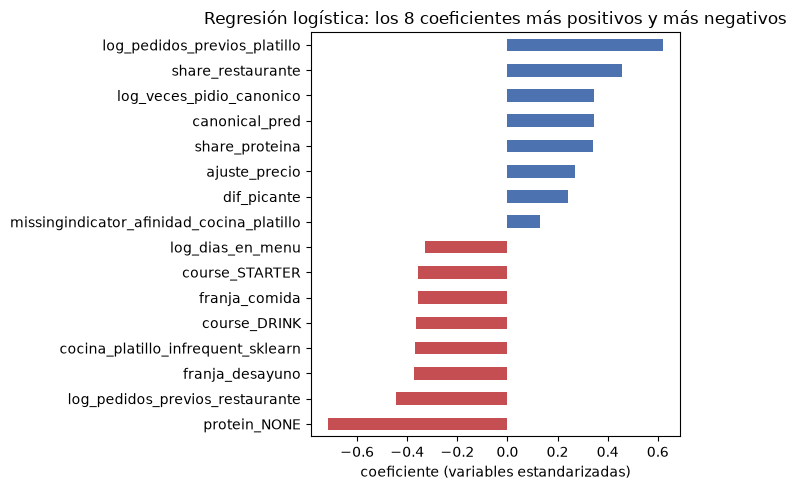

In [6]:
# Coeficientes: con variables estandarizadas, el tamaño compara cuánto pesa cada una.
nombres = logistica.named_steps["pre"].get_feature_names_out()
coef = pd.Series(logistica.named_steps["clf"].coef_[0], index=nombres)
coef.index = coef.index.str.replace(r"^(num|cat|te)__", "", regex=True)
top = pd.concat([coef.nlargest(8), coef.nsmallest(8)]).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
top.plot.barh(ax=ax, color=np.where(top > 0, "#4C72B0", "#C44E52"))
ax.set_title("Regresión logística: los 8 coeficientes más positivos y más negativos")
ax.set_xlabel("coeficiente (variables estandarizadas)")
fig.tight_layout()
fig.savefig(paths.figures / "11_coeficientes_logistica.png", dpi=150)

## 4. Comparación en validación: "para ti"

In [7]:
todos = pd.concat(resultados.values(), ignore_index=True)
tabla = summarize(todos, by="modelo").set_index("modelo").loc[list(resultados)]
tabla["cobertura@3"] = [catalog_coverage(valid.assign(score=s), k=3, seed=SEED) for s in
                        [random_score(valid, seed=SEED), popularity_score(valid, min_orders=N_BEST),
                         content_score(valid), p_valid]]
tabla.round(3)

,consultas,ndcg@3,hit@3,recall@3,map@3,ndcg@5,hit@5,recall@5,map@5,cobertura@3
modelo,,,,,,,,,,
azar,40056,0.462,0.603,0.603,0.414,0.546,0.807,0.807,0.460,0.894
popularidad,40056,0.656,0.794,0.794,0.609,0.707,0.915,0.915,0.637,0.581
contenido,40056,0.649,0.793,0.793,0.600,0.703,0.922,0.922,0.629,0.790
logística,40056,0.703,0.840,0.840,0.655,0.745,0.942,0.942,0.679,0.686


In [8]:
# Por segmento: NDCG@3.
for seg in ["course", "tramo_historia", "primera_vez_restaurante"]:
    display(summarize(todos, by=["modelo", seg]).pivot(index=seg, columns="modelo", values="ndcg@3")[list(resultados)].round(3))

modelo,azar,popularidad,contenido,logística
course,,,,
DESSERT,0.706,0.818,0.796,0.836
DRINK,0.432,0.660,0.589,0.686
MAIN,0.295,0.531,0.579,0.613
SIDE,0.909,0.938,0.925,0.943
STARTER,0.752,0.835,0.836,0.858


modelo,azar,popularidad,contenido,logística
tramo_historia,,,,
1-5,0.496,0.639,0.559,0.638
6-20,0.477,0.666,0.628,0.699
21+,0.458,0.654,0.655,0.704


modelo,azar,popularidad,contenido,logística
primera_vez_restaurante,,,,
False,0.458,0.655,0.662,0.706
True,0.472,0.661,0.618,0.696


## 5. "Para la mesa"

Mismos modelos, con las features de la mesa (`FOR_TABLE`). La popularidad aquí es la de **compartir**: tasa de compartido del canónico en la plataforma.

In [9]:
mesa = pd.read_parquet(paths.data_model / "para_la_mesa.parquet")
mesa = mesa[mesa["split"].isin(["train", "valid"])]
mtr, mva = mesa[mesa["split"] == "train"], mesa[mesa["split"] == "valid"]
Mtr, Mva = model_frame(mtr, FOR_TABLE), model_frame(mva, FOR_TABLE)
mcols = list(FOR_TABLE.columns)
log_mesa = make_logistic(FOR_TABLE, c=C_BEST, seed=SEED).fit(Mtr[mcols], Mtr["y"])
scores_mesa = {
    "azar": random_score(mva, seed=SEED),
    "popularidad de compartir": mva["tasa_compartido_canonico"],
    "logística": log_mesa.predict_proba(Mva[mcols])[:, 1],
}
res_mesa = pd.concat([rank_metrics(mva.assign(score=s), ks=(1, 3), seed=SEED).assign(modelo=k)
                      for k, s in scores_mesa.items()])
display(pd.Series({"mesas de validación": mva["query_id"].nunique(),
                   "candidatos por mesa (mediana)": mva.groupby("query_id").size().median()}).to_frame("valor").T)
summarize(res_mesa, by="modelo").set_index("modelo").loc[list(scores_mesa)].round(3)

,mesas de validación,candidatos por mesa (mediana)
valor,2866.0,2.0


,consultas,ndcg@1,hit@1,recall@1,map@1,ndcg@3,hit@3,recall@3,map@3
modelo,,,,,,,,,
azar,2866,0.612,0.612,0.612,0.612,0.816,0.950,0.950,0.769
popularidad de compartir,2866,0.740,0.740,0.740,0.740,0.878,0.967,0.967,0.847
logística,2866,0.833,0.833,0.833,0.833,0.926,0.983,0.983,0.905


Con una mediana de 2 candidatos, @3 casi siempre incluye todo, así que la métrica que distingue es **@1**: ¿el primero que se muestra es el que la mesa compartió?

## 6. Guardado

In [10]:
paths.models.mkdir(parents=True, exist_ok=True)
joblib.dump(logistica, paths.models / "logistica_para_ti.joblib")
joblib.dump(log_mesa, paths.models / "logistica_para_la_mesa.joblib")
todos.to_parquet(paths.data_model / "metricas_base_valid.parquet", index=False)
pd.Series({"N popularidad": N_BEST, "C logística": C_BEST}).to_frame("hiperparámetro elegido")

,hiperparámetro elegido
N popularidad,0.0
C logística,1.0


## Conclusiones

### 1. La vara que tiene que superar LightGBM ("para ti", validación)

| Modelo | NDCG@3 | HitRate@3 | MAP@3 | Cobertura@3 |
|---|---|---|---|---|
| Azar | 0.462 | 0.603 | 0.414 | 0.89 |
| Popularidad | 0.656 | 0.794 | 0.609 | 0.58 |
| Contenido | 0.649 | 0.793 | 0.600 | 0.79 |
| **Regresión logística** | **0.703** | **0.840** | **0.655** | 0.69 |

- **Lo simple ya funciona:** la popularidad sube el NDCG@3 de 0.46 a 0.66. Cualquier modelo tiene que superar **0.656**, no el azar.
- **Aprender sí aporta:** la regresión logística le gana a la popularidad por **0.047** de NDCG@3 (de 0.656 a 0.703), y en el 84 % de las consultas lo pedido queda en el top 3. Si el notebook 13 confirma que la diferencia es significativa, esta es la línea base contra la que se compara LightGBM.
- **Sesgo de popularidad:** la popularidad solo muestra el 58 % del catálogo en algún top 3; el contenido, el 79 %. La logística queda en medio (69 %). Recomendar siempre lo más pedido esconde platillos.

### 2. Lo difícil es el plato fuerte

| Tipo de plato | Azar | Logística |
|---|---|---|
| Guarnición | 0.91 | 0.94 |
| Entrada | 0.75 | 0.86 |
| Postre | 0.71 | 0.84 |
| Bebida | 0.43 | 0.69 |
| **Plato fuerte** | **0.30** | **0.61** |

En guarniciones, entradas y postres hay pocas opciones y casi cualquier orden acierta. El **plato fuerte** (menús más largos) y la **bebida** son donde el modelo tiene que ganarse el lugar. Por eso las métricas se reportan **por tipo de plato**, no solo en promedio.

### 3. Historia y primera visita

- **Con poca historia (1-5 visitas) la logística no le gana a la popularidad** (0.638 contra 0.639). Con más historia sí (0.704 contra 0.654 con 21+). Es lo esperable: sin historia, lo mejor que se sabe es qué es popular.
- **Primera vez en el restaurante:** la logística baja poco (0.696 contra 0.706). El contenido sí cae (0.618 contra 0.662), porque se apoya en haber pedido **ese** platillo antes. Lo que se transfiere entre restaurantes (canónico, proteína, picante) sostiene a la logística.

### 4. Dos hiperparámetros, y uno que no se pudo probar

- **C de la logística:** 0.01 y 1.0 dan prácticamente lo mismo (0.7026 contra 0.7027): con 2 millones de filas, la regularización casi no importa. Se usa 1.0.
- **N del respaldo de popularidad: 0.** Confiar siempre en la popularidad del restaurante, ya suavizada, es lo mejor. **Ojo:** en el mes 10 casi no hay restaurantes con poca historia (solo el 0.13 % de las consultas tiene menos de 10 pedidos previos), así que **el respaldo global no se puso a prueba**. Es el mismo problema del arranque en frío del notebook 10; se mide en el notebook 13 con el mismo enfoque contrafactual.

### 5. "Para la mesa"

| Modelo | Hit@1 |
|---|---|
| Azar | 0.61 |
| Popularidad de compartir | 0.74 |
| **Logística** | **0.83** |

Con 2 candidatos por mesa (mediana), el azar ya acierta el 61 % de las veces en el primer lugar, así que la métrica útil es **@1** y siempre contra el azar. La logística mejora 22 puntos sobre el azar y 9 sobre la popularidad: la composición de la mesa (gusto por compartir, alergias, picante) sí ayuda a elegir qué poner al centro.

**Pasa al notebook 12:** LightGBM LambdaRank con Optuna, con la misma información (`ranking/feature_sets.py`) y la misma validación.
